<a href="https://colab.research.google.com/github/Pujasatish001/DS-Lab-Experiments/blob/main/DS_Lab_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#Experiment 1:18-11-2026
import pandas as pd
import os
import json

# STEP 1: CREATE DATA IN THREE DIFFERENT FILE FORMATS

# CSV File - In-store billing system
csv_data = {
    "order_id": [101, 102, 103],
    "branch": ["Chennai", "Bangalore", "Chennai"],
    "product": ["Laptop", "Mouse", "Keyboard"],
    "quantity": [2, 5, 3],
    "unit_price": [50000, 500, 1500]
}

pd.DataFrame(csv_data).to_csv("pos_orders.csv", index=False)


# JSON File - Online store
json_data = [
    {"order_id": 104, "branch": "Mumbai", "product": "Mobile",
     "quantity": 2, "unit_price": 20000},
    {"order_id": 105, "branch": "Chennai", "product": "Tablet",
     "quantity": 1, "unit_price": 25000}
]

with open("web_orders.json", "w") as file:
    json.dump(json_data, file, indent=4)


# TEXT File - Mobile app
text_data = """order_id|branch|product|quantity|unit_price
106|Bangalore|Headphones|2|3000
107|Mumbai|Monitor|1|12000
"""

with open("mobile_orders.txt", "w") as file:
    file.write(text_data)


# STEP 2: READ DATA FROM THREE FILES

df_csv = pd.read_csv("pos_orders.csv")

df_json = pd.read_json("web_orders.json")

df_text = pd.read_csv("mobile_orders.txt", sep="|")


print("CSV DATA:")
print(df_csv)

print("\nJSON DATA:")
print(df_json)

print("\nTEXT DATA:")
print(df_text)


# STEP 3: INTEGRATE ALL THREE DATA SOURCES

df = pd.concat(
    [df_csv, df_json, df_text],
    ignore_index=True
)

# Derive order amount column
df["amount"] = df["quantity"] * df["unit_price"]

print("\nINTEGRATED DATASET:")
print(df)


# STEP 4: STORE DATA IN CSV, JSON AND EXCEL FORMATS

df.to_csv("integrated_orders.csv", index=False)

df.to_json("integrated_orders.json", orient="records", indent=4)

df.to_excel("integrated_orders.xlsx", index=False)


# STEP 5: REPORT FILE SIZES

print("\nFILE SIZES:")

files = [
    "integrated_orders.csv",
    "integrated_orders.json",
    "integrated_orders.xlsx"
]

for file in files:
    size = os.path.getsize(file)
    print(file, ":", size, "bytes")


# STEP 6: RETRIEVE STORED DATA

retrieved_data = pd.read_csv("integrated_orders.csv")

print("\nRETRIEVED DATA:")
print(retrieved_data)


# STEP 7: COMPUTE REVENUE BY BRANCH

branch_revenue = retrieved_data.groupby("branch")["amount"].sum()

print("\nREVENUE BY BRANCH:")
print(branch_revenue)


# STEP 8: DISPLAY HIGH-VALUE ORDERS

high_value_orders = retrieved_data[
    retrieved_data["amount"] >= 20000
]

print("\nHIGH-VALUE ORDERS (Amount >= 20000):")
print(high_value_orders)


# STEP 9: CONCLUSION

print("\nData Collection, Integration, Storage and Retrieval Completed Successfully!")


CSV DATA:
   order_id     branch   product  quantity  unit_price
0       101    Chennai    Laptop         2       50000
1       102  Bangalore     Mouse         5         500
2       103    Chennai  Keyboard         3        1500

JSON DATA:
   order_id   branch product  quantity  unit_price
0       104   Mumbai  Mobile         2       20000
1       105  Chennai  Tablet         1       25000

TEXT DATA:
   order_id     branch     product  quantity  unit_price
0       106  Bangalore  Headphones         2        3000
1       107     Mumbai     Monitor         1       12000

INTEGRATED DATASET:
   order_id     branch     product  quantity  unit_price  amount
0       101    Chennai      Laptop         2       50000  100000
1       102  Bangalore       Mouse         5         500    2500
2       103    Chennai    Keyboard         3        1500    4500
3       104     Mumbai      Mobile         2       20000   40000
4       105    Chennai      Tablet         1       25000   25000
5       106

In [ ]:
#Experiment 2: 18-11-2026
import sqlite3
import pandas as pd
import json

# STEP 1: CONNECT TO SQLITE DATABASE

conn = sqlite3.connect("hospital.db")
cursor = conn.cursor()

# STEP 2: CREATE TABLES

cursor.execute("""
CREATE TABLE IF NOT EXISTS DOCTORS (
    doctor_id INTEGER PRIMARY KEY,
    name TEXT,
    department TEXT
)
""")

cursor.execute("""
CREATE TABLE IF NOT EXISTS PATIENTS (
    patient_id INTEGER PRIMARY KEY,
    name TEXT,
    age INTEGER,
    gender TEXT,
    city TEXT
)
""")

cursor.execute("""
CREATE TABLE IF NOT EXISTS VISITS (
    visit_id INTEGER PRIMARY KEY,
    patient_id INTEGER,
    doctor_id INTEGER,
    visit_date TEXT,
    fee REAL,
    FOREIGN KEY (patient_id) REFERENCES PATIENTS(patient_id),
    FOREIGN KEY (doctor_id) REFERENCES DOCTORS(doctor_id)
)
""")

# STEP 3: INSERT RECORDS

doctors = [
    (1, "Dr. Ravi", "Cardiology"),
    (2, "Dr. Priya", "Neurology"),
    (3, "Dr. Kumar", "Orthopedics")
]

patients = [
    (101, "Arun", 25, "Male", "Chennai"),
    (102, "Meena", 30, "Female", "Coimbatore"),
    (103, "Rahul", 45, "Male", "Chennai"),
    (104, "Divya", 35, "Female", "Madurai")
]

visits = [
    (1, 101, 1, "2026-01-10", 1500),
    (2, 102, 2, "2026-01-11", 2000),
    (3, 103, 1, "2026-01-12", 2500),
    (4, 104, 3, "2026-01-13", 1800),
    (5, 101, 2, "2026-01-15", 2000)
]

cursor.executemany(
    "INSERT OR IGNORE INTO DOCTORS VALUES (?, ?, ?)", doctors
)

cursor.executemany(
    "INSERT OR IGNORE INTO PATIENTS VALUES (?, ?, ?, ?, ?)", patients
)

cursor.executemany(
    "INSERT OR IGNORE INTO VISITS VALUES (?, ?, ?, ?, ?)", visits
)

conn.commit()

print("Records inserted successfully!")


# STEP 4: SELECT QUERY

print("\nALL PATIENTS:")

cursor.execute("SELECT * FROM PATIENTS")
print(cursor.fetchall())


# STEP 5: JOIN QUERY

print("\nPATIENT VISIT DETAILS:")

join_query = """
SELECT
    PATIENTS.name,
    DOCTORS.name,
    DOCTORS.department,
    VISITS.visit_date,
    VISITS.fee
FROM VISITS
JOIN PATIENTS
ON VISITS.patient_id = PATIENTS.patient_id
JOIN DOCTORS
ON VISITS.doctor_id = DOCTORS.doctor_id
"""

cursor.execute(join_query)

for row in cursor.fetchall():
    print(row)


# STEP 6: GROUP BY QUERY

print("\nTOTAL REVENUE BY DOCTOR:")

cursor.execute("""
SELECT doctor_id, SUM(fee)
FROM VISITS
GROUP BY doctor_id
""")

for row in cursor.fetchall():
    print(row)


# STEP 7: HAVING QUERY

print("\nDOCTORS WITH TOTAL FEES ABOVE 3000:")

cursor.execute("""
SELECT doctor_id, SUM(fee)
FROM VISITS
GROUP BY doctor_id
HAVING SUM(fee) > 3000
""")

for row in cursor.fetchall():
    print(row)


# STEP 8: UPDATE OPERATION

cursor.execute("""
UPDATE PATIENTS
SET city = 'Bangalore'
WHERE patient_id = 101
""")

conn.commit()

print("\nAFTER UPDATE:")

cursor.execute("""
SELECT * FROM PATIENTS WHERE patient_id = 101
""")

print(cursor.fetchall())


# STEP 9: DELETE OPERATION

cursor.execute("""
DELETE FROM VISITS
WHERE visit_id = 4
""")

conn.commit()

print("\nAFTER DELETE:")

cursor.execute("""
SELECT * FROM VISITS
WHERE visit_id = 4
""")

print(cursor.fetchall())


# STEP 10: LOAD SQL RESULTS INTO PANDAS DATAFRAME

df = pd.read_sql_query(join_query, conn)

print("\nPANDAS DATAFRAME:")
print(df)


# STEP 11: CONVERT RELATIONAL DATA INTO JSON DOCUMENTS

patients_df = pd.read_sql_query(
    "SELECT * FROM PATIENTS", conn
)

visits_df = pd.read_sql_query(
    "SELECT * FROM VISITS", conn
)

doctors_df = pd.read_sql_query(
    "SELECT * FROM DOCTORS", conn
)

# Create MongoDB-style patient documents
documents = []

for _, patient in patients_df.iterrows():

    patient_visits = visits_df[
        visits_df["patient_id"] == patient["patient_id"]
    ]

    visit_list = []

    for _, visit in patient_visits.iterrows():

        doctor = doctors_df[
            doctors_df["doctor_id"] == visit["doctor_id"]
        ].iloc[0]

        visit_list.append({
            "visit_id": int(visit["visit_id"]),
            "doctor": doctor["name"],
            "department": doctor["department"],
            "visit_date": visit["visit_date"],
            "fee": float(visit["fee"])
        })

    patient_document = {
        "patient_id": int(patient["patient_id"]),
        "name": patient["name"],
        "age": int(patient["age"]),
        "gender": patient["gender"],
        "city": patient["city"],
        "visits": visit_list
    }

    documents.append(patient_document)


# Store documents in JSON file

with open("hospital_documents.json", "w") as file:
    json.dump(documents, file, indent=4)

print("\nJSON DOCUMENTS CREATED SUCCESSFULLY!")

print(json.dumps(documents, indent=4))


# STEP 12: QUERY NOSQL DOCUMENTS

print("\nNOSQL QUERY - PATIENTS FROM CHENNAI:")

with open("hospital_documents.json", "r") as file:
    nosql_data = json.load(file)

for patient in nosql_data:
    if patient["city"] == "Chennai":
        print(patient)


# STEP 13: QUERY PATIENTS WITH HIGH-VALUE VISITS

print("\nPATIENTS WITH VISIT FEE ABOVE 1500:")

for patient in nosql_data:
    for visit in patient["visits"]:
        if visit["fee"] > 1500:
            print(patient["name"], visit)


# STEP 14: COMPARE RELATIONAL AND NOSQL MODELS

print("\nRELATIONAL DATABASE:")
print("Data is stored in separate tables.")
print("Relationships are maintained using primary and foreign keys.")
print("SQL JOIN is used to retrieve related information.")

print("\nNOSQL DOCUMENT DATABASE:")
print("Data is stored in JSON documents.")
print("Patient information and visits are embedded together.")
print("Nested documents can be retrieved without SQL JOIN.")


# STEP 15: CLOSE DATABASE CONNECTION

conn.close()

print("\nEXPERIMENT 2 COMPLETED SUCCESSFULLY!")


Records inserted successfully!

ALL PATIENTS:
[(101, 'Arun', 25, 'Male', 'Chennai'), (102, 'Meena', 30, 'Female', 'Coimbatore'), (103, 'Rahul', 45, 'Male', 'Chennai'), (104, 'Divya', 35, 'Female', 'Madurai')]

PATIENT VISIT DETAILS:
('Arun', 'Dr. Ravi', 'Cardiology', '2026-01-10', 1500.0)
('Meena', 'Dr. Priya', 'Neurology', '2026-01-11', 2000.0)
('Rahul', 'Dr. Ravi', 'Cardiology', '2026-01-12', 2500.0)
('Divya', 'Dr. Kumar', 'Orthopedics', '2026-01-13', 1800.0)
('Arun', 'Dr. Priya', 'Neurology', '2026-01-15', 2000.0)

TOTAL REVENUE BY DOCTOR:
(1, 4000.0)
(2, 4000.0)
(3, 1800.0)

DOCTORS WITH TOTAL FEES ABOVE 3000:
(1, 4000.0)
(2, 4000.0)

AFTER UPDATE:
[(101, 'Arun', 25, 'Male', 'Bangalore')]

AFTER DELETE:
[]

PANDAS DATAFRAME:
    name       name  department  visit_date     fee
0   Arun   Dr. Ravi  Cardiology  2026-01-10  1500.0
1  Meena  Dr. Priya   Neurology  2026-01-11  2000.0
2  Rahul   Dr. Ravi  Cardiology  2026-01-12  2500.0
3   Arun  Dr. Priya   Neurology  2026-01-15  2000.0



STUDENT PERFORMANCE DATASET:
    Gender Department Grade  Attendance  Study_Hours  Marks
0     Male         IT     D          86          5.8     35
1   Female         IT     A          96          5.4     82
2     Male        CSE     B          63          7.2     46
3     Male        CSE     C          52          3.4     71
4     Male         IT     A          50          3.2     66
5   Female        ECE     D          54          2.5     43
6     Male       MECH     B          75          3.0     53
7     Male        CSE     A          63          6.0     82
8     Male       MECH     D          88          4.6     37
9   Female        ECE     D          76          1.6     54
10    Male        ECE     D          58          3.3     58
11    Male        ECE     A          64          3.2     88
12    Male        CSE     A          64          7.3     67
13    Male        ECE     A          75          7.4     58
14  Female        CSE     C          91          2.3     70
15    Male 

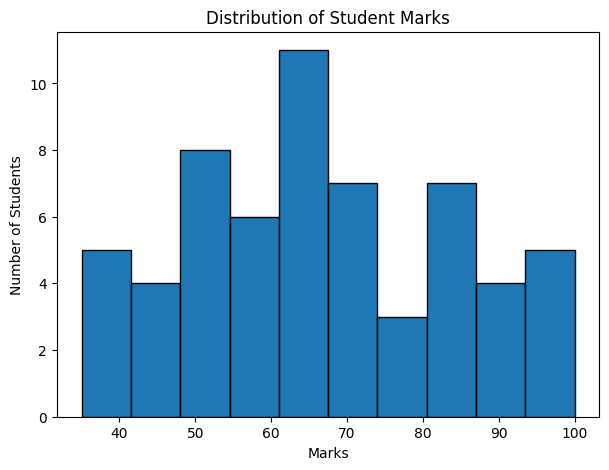

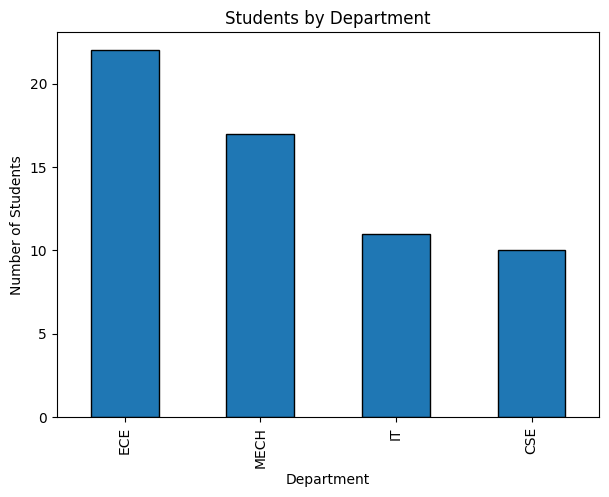

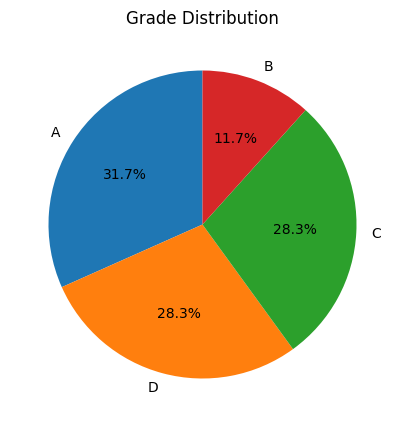

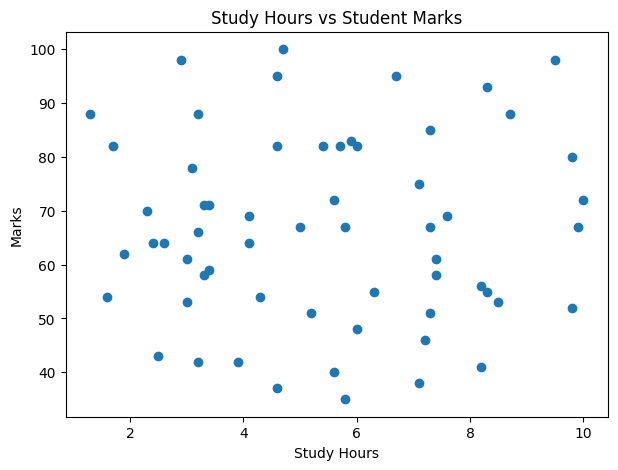


INTERPRETATION:
Correlation between study hours and marks: 0.012
There is a positive relationship between study hours and marks.

EXPLORATORY DATA ANALYSIS COMPLETED SUCCESSFULLY!


In [ ]:
#Experment 3: 19-11-2026
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# STEP 1: CREATE STUDENT PERFORMANCE DATASET

np.random.seed(42)

n = 60

data = {
    "Gender": np.random.choice(
        ["Male", "Female"], n
    ),

    "Department": np.random.choice(
        ["CSE", "ECE", "IT", "MECH"], n
    ),

    "Grade": np.random.choice(
        ["A", "B", "C", "D"], n
    ),

    "Attendance": np.random.randint(
        50, 101, n
    ),

    "Study_Hours": np.round(
        np.random.uniform(1, 10, n), 1
    ),

    "Marks": np.random.randint(
        35, 101, n
    )
}

df = pd.DataFrame(data)

# Save dataset
df.to_csv("student_performance.csv", index=False)

print("STUDENT PERFORMANCE DATASET:")
print(df)

print("\nDATASET INFORMATION:")
print(df.info())


# STEP 2: CLASSIFY ATTRIBUTES

print("\nATTRIBUTE CLASSIFICATION:")

classification = {
    "Gender": "Nominal",
    "Department": "Nominal",
    "Grade": "Ordinal",
    "Attendance": "Continuous",
    "Study_Hours": "Continuous",
    "Marks": "Continuous"
}

for attribute, category in classification.items():
    print(attribute, ":", category)


# STEP 3: DESCRIPTIVE STATISTICS

print("\nDESCRIPTIVE STATISTICS:")

print("\nMean:")
print(df[["Attendance", "Study_Hours", "Marks"]].mean())

print("\nMedian:")
print(df[["Attendance", "Study_Hours", "Marks"]].median())

print("\nMode:")
print(df.mode().iloc[0])

print("\nStandard Deviation:")
print(df[["Attendance", "Study_Hours", "Marks"]].std())

print("\nQuartiles:")
print(df[["Attendance", "Study_Hours", "Marks"]].quantile(
    [0.25, 0.50, 0.75]
))

print("\nSkewness:")
print(df[["Attendance", "Study_Hours", "Marks"]].skew())


# STEP 4: FREQUENCY TABLES

print("\nGENDER FREQUENCY:")
print(df["Gender"].value_counts())

print("\nDEPARTMENT FREQUENCY:")
print(df["Department"].value_counts())

print("\nGRADE FREQUENCY:")
print(df["Grade"].value_counts())


# STEP 5: CROSS-TABULATION

print("\nCROSS TABULATION (DEPARTMENT VS GRADE):")

cross_tab = pd.crosstab(
    df["Department"],
    df["Grade"]
)

print(cross_tab)


# STEP 6: CORRELATION MATRIX

print("\nCORRELATION MATRIX:")

correlation = df[
    ["Attendance", "Study_Hours", "Marks"]
].corr()

print(correlation)


# STEP 7: HISTOGRAM

plt.figure(figsize=(7, 5))

plt.hist(
    df["Marks"],
    bins=10,
    edgecolor="black"
)

plt.title("Distribution of Student Marks")
plt.xlabel("Marks")
plt.ylabel("Number of Students")
plt.show()


# STEP 8: BAR CHART

plt.figure(figsize=(7, 5))

df["Department"].value_counts().plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Students by Department")
plt.xlabel("Department")
plt.ylabel("Number of Students")
plt.show()


# STEP 9: PIE CHART

plt.figure(figsize=(7, 5))

df["Grade"].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Grade Distribution")
plt.ylabel("")
plt.show()


# STEP 10: SCATTER PLOT

plt.figure(figsize=(7, 5))

plt.scatter(
    df["Study_Hours"],
    df["Marks"]
)

plt.title("Study Hours vs Student Marks")
plt.xlabel("Study Hours")
plt.ylabel("Marks")
plt.show()


# STEP 11: INTERPRETATION

print("\nINTERPRETATION:")

r = df["Study_Hours"].corr(df["Marks"])

print("Correlation between study hours and marks:", round(r, 3))

if r > 0:
    print("There is a positive relationship between study hours and marks.")
elif r < 0:
    print("There is a negative relationship between study hours and marks.")
else:
    print("There is no linear relationship between study hours and marks.")

print("\nEXPLORATORY DATA ANALYSIS COMPLETED SUCCESSFULLY!")


In [ ]:
#Experiment 4:19-11-2026
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# STEP 1: CREATE RAW CUSTOMER DATASET

np.random.seed(42)

n = 100

data = {
    "Customer_ID": range(1, n + 1),

    "Age": np.random.randint(18, 65, n),

    "Monthly_Income": np.random.randint(15000, 100000, n),

    "Tenure": np.random.randint(1, 72, n),

    "City": np.random.choice(
        ["Chennai", "Mumbai", "Delhi", "Bangalore"], n
    ),

    "Gender": np.random.choice(
        ["Male", "Female"], n
    ),

    "Contract": np.random.choice(
        ["Monthly", "Yearly", "Two Year"], n
    ),

    "Churn": np.random.choice(
        [0, 1], n, p=[0.7, 0.3]
    )
}

df = pd.DataFrame(data)

# Introduce missing values
df.loc[[2, 5, 10, 15], "Age"] = np.nan
df.loc[[3, 8, 12, 20], "Monthly_Income"] = np.nan

# Introduce duplicate record
df = pd.concat([df, df.iloc[[0]]], ignore_index=True)

# Introduce inconsistent categories
df.loc[4, "City"] = "chennai"
df.loc[7, "City"] = " CHENNAI "
df.loc[9, "City"] = "BENGALURU"
df.loc[11, "Contract"] = "monthly"

# Introduce invalid negative values
df.loc[13, "Age"] = -5
df.loc[14, "Monthly_Income"] = -1000

# Introduce extreme outliers
df.loc[16, "Age"] = 150
df.loc[17, "Monthly_Income"] = 999999

print("RAW CUSTOMER DATA:")
print(df.head(10))


# STEP 2: DETECT MISSING VALUES

print("\nMISSING VALUES:")

print(df.isnull().sum())


# STEP 3: DETECT DUPLICATE RECORDS

print("\nNUMBER OF DUPLICATES:")

print(df.duplicated().sum())

# Remove duplicate records
df = df.drop_duplicates()

print("Duplicates removed successfully!")


# STEP 4: CORRECT INCONSISTENT CATEGORIES

df["City"] = df["City"].str.strip().str.title()

df["City"] = df["City"].replace({
    "Bengaluru": "Bangalore"
})

df["Contract"] = df["Contract"].str.strip().str.title()

print("\nCLEANED CATEGORIES:")

print(df["City"].unique())
print(df["Contract"].unique())


# STEP 5: HANDLE INVALID NEGATIVE VALUES

df.loc[df["Age"] < 0, "Age"] = np.nan

df.loc[df["Monthly_Income"] < 0, "Monthly_Income"] = np.nan

print("\nINVALID VALUES CONVERTED TO MISSING VALUES.")


# STEP 6: SIMPLE RANDOM SAMPLING

random_sample = df.sample(n=10, random_state=42)

print("\nSIMPLE RANDOM SAMPLE OF 10 CUSTOMERS:")

print(random_sample)


# STEP 7: SPLIT DATA INTO TRAIN, VALIDATION AND TEST

train_data, temp_data = train_test_split(
    df,
    test_size=0.30,
    random_state=42,
    stratify=df["Churn"]
)

validation_data, test_data = train_test_split(
    temp_data,
    test_size=0.50,
    random_state=42,
    stratify=temp_data["Churn"]
)

print("\nDATASET SPLIT:")

print("Training records:", len(train_data))
print("Validation records:", len(validation_data))
print("Testing records:", len(test_data))


# STEP 8: SEPARATE FEATURES AND TARGET

target = "Churn"

X_train = train_data.drop(columns=["Churn", "Customer_ID"]).copy()
X_val = validation_data.drop(columns=["Churn", "Customer_ID"]).copy()
X_test = test_data.drop(columns=["Churn", "Customer_ID"]).copy()

y_train = train_data[target].copy()
y_val = validation_data[target].copy()
y_test = test_data[target].copy()

numeric_cols = ["Age", "Monthly_Income", "Tenure"]

categorical_cols = ["City", "Gender", "Contract"]


# STEP 9: DETECT AND TREAT OUTLIERS USING IQR

print("\nOUTLIER DETECTION USING IQR:")

lower_bounds = {}
upper_bounds = {}

for col in numeric_cols:

    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    lower_bounds[col] = lower
    upper_bounds[col] = upper

    outliers = X_train[
        (X_train[col] < lower) |
        (X_train[col] > upper)
    ]

    print(col, ":", len(outliers), "outliers")

    # Treat outliers by capping extreme values
    for dataset in [X_train, X_val, X_test]:

        dataset[col] = dataset[col].clip(
            lower=lower,
            upper=upper
        )


# STEP 10: IMPUTE MISSING VALUES USING MEDIAN AND MEAN

for col in numeric_cols:

    if col in ["Age", "Tenure"]:
        fill_value = X_train[col].median()

    else:
        fill_value = X_train[col].mean()

    for dataset in [X_train, X_val, X_test]:
        dataset[col] = dataset[col].fillna(fill_value)

    print(col, "imputed value:", round(fill_value, 2))


# Impute missing categorical values using mode

for col in categorical_cols:

    fill_value = X_train[col].mode()[0]

    for dataset in [X_train, X_val, X_test]:
        dataset[col] = dataset[col].fillna(fill_value)


print("\nMISSING VALUES AFTER IMPUTATION:")

print(X_train.isnull().sum())


# STEP 11: ENCODE CATEGORICAL VARIABLES

encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

encoder.fit(X_train[categorical_cols])

train_encoded = encoder.transform(
    X_train[categorical_cols]
)

val_encoded = encoder.transform(
    X_val[categorical_cols]
)

test_encoded = encoder.transform(
    X_test[categorical_cols]
)

encoded_columns = encoder.get_feature_names_out(
    categorical_cols
)


# STEP 12: STANDARDISE NUMERICAL FEATURES

scaler = StandardScaler()

train_scaled = scaler.fit_transform(
    X_train[numeric_cols]
)

val_scaled = scaler.transform(
    X_val[numeric_cols]
)

test_scaled = scaler.transform(
    X_test[numeric_cols]
)


# Combine encoded and scaled features

X_train_final = pd.DataFrame(
    np.hstack([train_scaled, train_encoded]),
    columns=numeric_cols + list(encoded_columns),
    index=X_train.index
)

X_val_final = pd.DataFrame(
    np.hstack([val_scaled, val_encoded]),
    columns=numeric_cols + list(encoded_columns),
    index=X_val.index
)

X_test_final = pd.DataFrame(
    np.hstack([test_scaled, test_encoded]),
    columns=numeric_cols + list(encoded_columns),
    index=X_test.index
)

print("\nENCODED AND STANDARDISED TRAINING DATA:")

print(X_train_final.head())


# STEP 13: REPORT CLASS DISTRIBUTION

print("\nCHURN CLASS DISTRIBUTION:")

print("Original Dataset:")
print(df["Churn"].value_counts(normalize=True))

print("\nTraining Dataset:")
print(y_train.value_counts(normalize=True))

print("\nValidation Dataset:")
print(y_val.value_counts(normalize=True))

print("\nTesting Dataset:")
print(y_test.value_counts(normalize=True))


# STEP 14: SAVE PROCESSED DATASETS

X_train_final.to_csv("training_data.csv", index=False)

X_val_final.to_csv("validation_data.csv", index=False)

X_test_final.to_csv("testing_data.csv", index=False)

print("\nPROCESSED DATASETS SAVED SUCCESSFULLY!")


# STEP 15: FINAL RESULT

print("\nDATA CLEANING AND SAMPLING COMPLETED SUCCESSFULLY!")

print("Training Data:", X_train_final.shape)
print("Validation Data:", X_val_final.shape)
print("Testing Data:", X_test_final.shape)

RAW CUSTOMER DATA:
   Customer_ID   Age  Monthly_Income  Tenure       City  Gender  Contract  \
0            1  56.0         17695.0      68  Bangalore    Male    Yearly   
1            2  46.0         63190.0      55    Chennai  Female    Yearly   
2            3   NaN         20258.0      56    Chennai    Male   Monthly   
3            4  60.0             NaN      17     Mumbai  Female    Yearly   
4            5  25.0         48159.0      38    chennai  Female  Two Year   
5            6   NaN         28986.0      24      Delhi  Female    Yearly   
6            7  56.0         76858.0      69      Delhi    Male    Yearly   
7            8  36.0         27666.0      70   CHENNAI     Male  Two Year   
8            9  40.0             NaN      11    Chennai  Female    Yearly   
9           10  28.0         18561.0      16  BENGALURU  Female   Monthly   

   Churn  
0      0  
1      0  
2      0  
3      0  
4      1  
5      1  
6      0  
7      1  
8      1  
9      1  

MISSING VAL